# Final comparison — all models, both strategies

Builds the headline leaderboard and per-class heatmap from the JSON
results saved by each per-model notebook. Tolerates missing JSONs --
models not yet trained are skipped, not errors.

Anchors used downstream by the report:
- `test_macro_f1` leaderboard (Table 1)
- Strategy A vs B delta on test macro F1 (Figure 1)
- Per-class F1 heatmap (Figure 2)


## Cell 1 — Setup


In [1]:
# ============================================================================
# Cell 1 — Setup
# ============================================================================
import sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().resolve()
while not (PROJECT_ROOT / 'config.json').is_file():
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT / '_shared'))

from data import load_splits
splits = load_splits('A')
class_names = list(splits.class_names)
print(f'Project root: {PROJECT_ROOT}')


Project root: /Users/amrabdullah/AI_2026ss/mlpc


## Cell 2 — Discover and load all per-model JSONs
Convention: each model writes `NN_modelname.json` to
`strategy_X/artifacts/results/`. We iterate both strategies and
the known model list. Missing files are silently skipped.


In [2]:
# ============================================================================
# Cell 2 — Load every results JSON we can find
# ============================================================================
MODEL_REGISTRY = [
    # (model_key, filename_prefix, display_name)
    ('prior',  '02b_random',  'Empirical Prior'),
    ('logreg', '03_logreg',   'Logistic Regression'),
    ('rf',     '04_rf',       'Random Forest'),
    ('xgb',    '05_xgboost',  'XGBoost'),
    ('mlp_v1', '06_mlp',      'MLP v1'),
    ('mlp_v2', '07_mlp',      'MLP v2'),
    ('cnn',    '08_cnn',      'CNN'),
    ('lstm',   '09_lstm',     'CRNN'),
    ('ast',    '10_ast',      'AST (linear probe)'),
]
STRATEGIES = ['A', 'B']

def results_dir(strat):
    name = f'strategy_{strat}_baseline' if strat == 'A' else 'strategy_B_with_aug'
    return PROJECT_ROOT / name / 'artifacts' / 'results'

def extract_headline(j):
    '''Pull the macro/micro/weighted F1 out of any of the schemas
    in this project (LogReg/RF/XGB use one layout, MLP/CNN/LSTM/AST another).'''
    if 'headline_test' in j:
        h = j['headline_test']
        return h.get('macro_f1'), h.get('micro_f1'), h.get('weighted_f1')
    # older schemas (RF/XGB/LogReg): test_report has the aggregates
    tr = j.get('test_report', {})
    if 'f1' in tr.get('macro avg', {}):
        return (tr['macro avg']['f1'], tr['micro avg']['f1'],
                tr['weighted avg']['f1'])
    return None, None, None

rows = []
per_class = {}    # (model_key, strategy) -> {class: f1}
for strat in STRATEGIES:
    rdir = results_dir(strat)
    for key, prefix, display in MODEL_REGISTRY:
        path = rdir / f'{prefix}.json'
        if not path.is_file():
            continue
        with open(path) as f:
            j = json.load(f)
        macro, micro, weighted = extract_headline(j)
        rows.append({
            'model':       display,
            'model_key':   key,
            'strategy':    strat,
            'macro_f1':    macro,
            'micro_f1':    micro,
            'weighted_f1': weighted,
        })
        # per-class
        tr = j.get('test_report', {})
        pc = {c: tr.get(c, {}).get('f1') for c in class_names
              if c in tr}
        if pc:
            per_class[(key, strat)] = pc

df = pd.DataFrame(rows)
print(f'Loaded {len(df)} model-strategy combinations:')
print(df.to_string(index=False))


Loaded 14 model-strategy combinations:
              model model_key strategy  macro_f1  micro_f1  weighted_f1
    Empirical Prior     prior        A    0.0531    0.0785       0.0790
Logistic Regression    logreg        A    0.4723    0.5658       0.5750
      Random Forest        rf        A    0.5040    0.5910       0.5929
            XGBoost       xgb        A    0.5605    0.6497       0.6526
             MLP v1    mlp_v1        A    0.4143    0.4985       0.5138
             MLP v2    mlp_v2        A    0.5495    0.6462       0.6477
                CNN       cnn        A    0.6035    0.6881       0.6895
               CRNN      lstm        A    0.6048    0.6857       0.6871
 AST (linear probe)       ast        A    0.5859    0.6532       0.6798
Logistic Regression    logreg        B    0.4749    0.5661       0.5736
      Random Forest        rf        B    0.4982    0.5832       0.5884
            XGBoost       xgb        B    0.5564    0.6458       0.6496
             MLP v1    ml

## Cell 3 — Headline leaderboard
Pivots into one row per model, A vs B columns, plus delta.


In [3]:
# ============================================================================
# Cell 3 — Build the cross-strategy leaderboard
# ============================================================================
if df.empty:
    print('No results found; train at least one model first.')
else:
    leaderboard = (df.pivot_table(index=['model_key', 'model'],
                                  columns='strategy',
                                  values='macro_f1')
                     .reset_index())
    if 'A' in leaderboard.columns and 'B' in leaderboard.columns:
        leaderboard['delta_B_A'] = leaderboard['B'] - leaderboard['A']
    leaderboard = leaderboard.rename(columns={
        'A': 'test_macro_f1_A',
        'B': 'test_macro_f1_B'})
    leaderboard = leaderboard.sort_values('test_macro_f1_A',
                                         ascending=False)
    print('Test macro F1 by model and strategy:\n')
    print(leaderboard.to_string(index=False, float_format='%.4f'))
    out_csv = PROJECT_ROOT / 'report' / 'tables' / 'leaderboard.csv'
    out_csv.parent.mkdir(parents=True, exist_ok=True)
    leaderboard.to_csv(out_csv, index=False)
    print(f'\nSaved -> {out_csv}')


Test macro F1 by model and strategy:

model_key               model  test_macro_f1_A  test_macro_f1_B  delta_B_A
     lstm                CRNN           0.6048              NaN        NaN
      cnn                 CNN           0.6035              NaN        NaN
      ast  AST (linear probe)           0.5859              NaN        NaN
      xgb             XGBoost           0.5605           0.5564    -0.0041
   mlp_v2              MLP v2           0.5495           0.5534     0.0039
       rf       Random Forest           0.5040           0.4982    -0.0058
   logreg Logistic Regression           0.4723           0.4749     0.0026
   mlp_v1              MLP v1           0.4143           0.4271     0.0128
    prior     Empirical Prior           0.0531              NaN        NaN

Saved -> /Users/amrabdullah/AI_2026ss/mlpc/report/tables/leaderboard.csv


## Cell 4 — Grouped bar chart (A vs B per model)


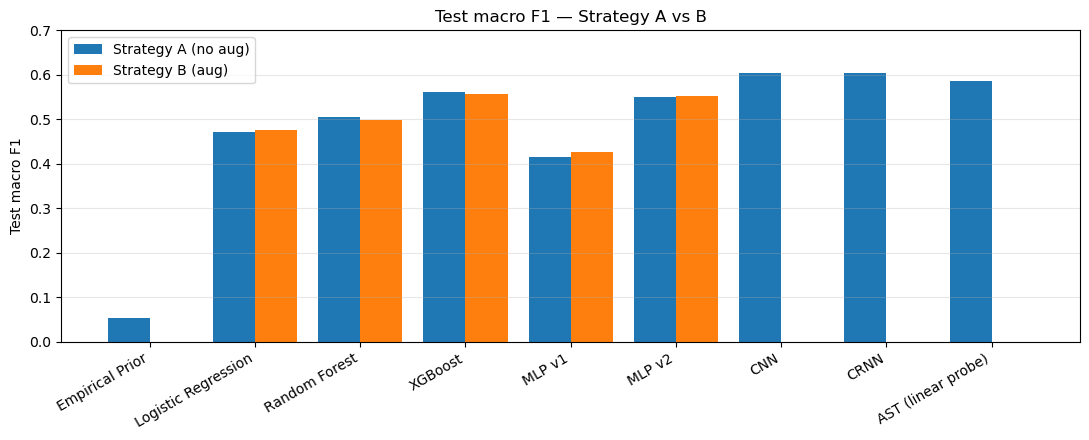

Saved -> /Users/amrabdullah/AI_2026ss/mlpc/report/figures/leaderboard_bar.png


In [4]:
# ============================================================================
# Cell 4 — Bar chart
# ============================================================================
if not df.empty:
    fig_dir = PROJECT_ROOT / 'report' / 'figures'
    fig_dir.mkdir(parents=True, exist_ok=True)

    piv = df.pivot_table(index='model', columns='strategy', values='macro_f1')
    # Preserve the registry order for x-axis
    ordered = [d for _, _, d in MODEL_REGISTRY if d in piv.index]
    piv = piv.loc[ordered]

    fig, ax = plt.subplots(figsize=(11, 4.5))
    x = np.arange(len(piv))
    w = 0.4
    if 'A' in piv.columns:
        ax.bar(x - w/2, piv['A'].fillna(0), w, label='Strategy A (no aug)',
               color='#1f77b4')
    if 'B' in piv.columns:
        ax.bar(x + w/2, piv['B'].fillna(0), w, label='Strategy B (aug)',
               color='#ff7f0e')
    ax.set_xticks(x); ax.set_xticklabels(piv.index, rotation=30, ha='right')
    ax.set_ylabel('Test macro F1'); ax.set_ylim(0, max(0.7, piv.max().max() * 1.1))
    ax.set_title('Test macro F1 — Strategy A vs B')
    ax.legend(); ax.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.savefig(fig_dir / 'leaderboard_bar.png', dpi=150, bbox_inches='tight')
    plt.show()
    print(f'Saved -> {fig_dir / "leaderboard_bar.png"}')


## Cell 5 — Per-class F1 heatmap (Strategy A only, all models)


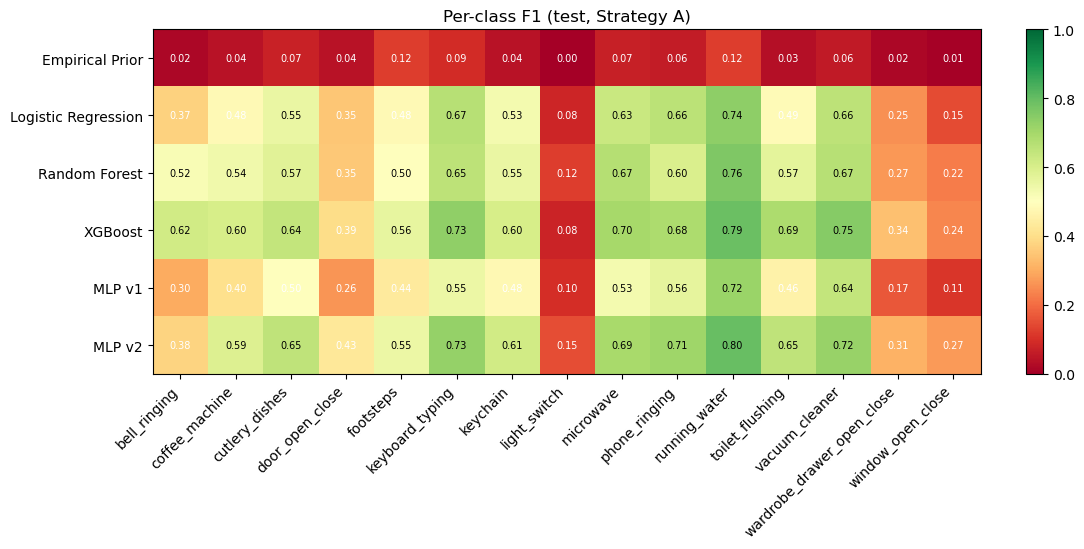

Saved -> /Users/amrabdullah/AI_2026ss/mlpc/report/figures/per_class_heatmap.png


In [5]:
# ============================================================================
# Cell 5 — Per-class F1 heatmap
# ============================================================================
if per_class:
    keys_A = [(k, 'A') for k, _, _ in MODEL_REGISTRY if (k, 'A') in per_class]
    if not keys_A:
        print('No per-class data for Strategy A yet.')
    else:
        rows = [per_class[k] for k in keys_A]
        names = [d for k, _, d in MODEL_REGISTRY if (k, 'A') in per_class]
        mat = np.array([[r.get(c, np.nan) for c in class_names] for r in rows])
        fig, ax = plt.subplots(figsize=(11, 0.6 * len(names) + 2))
        im = ax.imshow(mat, cmap='RdYlGn', vmin=0, vmax=1, aspect='auto')
        ax.set_xticks(range(len(class_names)))
        ax.set_xticklabels(class_names, rotation=45, ha='right')
        ax.set_yticks(range(len(names))); ax.set_yticklabels(names)
        for i in range(mat.shape[0]):
            for j in range(mat.shape[1]):
                v = mat[i, j]
                if not np.isnan(v):
                    ax.text(j, i, f'{v:.2f}', ha='center', va='center',
                            fontsize=7, color='black' if v > 0.5 else 'white')
        ax.set_title('Per-class F1 (test, Strategy A)')
        plt.colorbar(im, ax=ax, fraction=0.025)
        plt.tight_layout()
        plt.savefig(fig_dir / 'per_class_heatmap.png', dpi=150, bbox_inches='tight')
        plt.show()
        print(f'Saved -> {fig_dir / "per_class_heatmap.png"}')
else:
    print('per_class is empty; train models first.')


## Cell 6 — Report snippet (auto-generated)
Drop straight into Section 3 of the LaTeX report.


In [6]:
# ============================================================================
# Cell 6 — Auto-generate a report snippet
# ============================================================================
if df.empty:
    print('No results to summarize.')
else:
    lines = []
    lines.append('% Auto-generated by 11_final_comparison.ipynb')
    lines.append('')
    if 'A' in piv.columns:
        best_a = piv['A'].idxmax()
        lines.append(f'\\textbf{{Best Strategy A model:}} {best_a} (test macro F1 = '
                     f'{piv["A"].loc[best_a]:.4f}).')
    if 'B' in piv.columns:
        deltas = (piv['B'] - piv['A']).dropna()
        if len(deltas):
            lines.append(f'\\textbf{{Strategy B deltas:}} range '
                         f'[{deltas.min():+.4f}, {deltas.max():+.4f}], '
                         f'mean {deltas.mean():+.4f}.')
    snippet = '\n'.join(lines)
    print(snippet)
    snippet_path = PROJECT_ROOT / 'report' / 'tables' / 'comparison_snippet.tex'
    snippet_path.write_text(snippet)
    print(f'\nSaved -> {snippet_path}')


% Auto-generated by 11_final_comparison.ipynb

\textbf{Best Strategy A model:} CRNN (test macro F1 = 0.6048).
\textbf{Strategy B deltas:} range [-0.0058, +0.0128], mean +0.0019.

Saved -> /Users/amrabdullah/AI_2026ss/mlpc/report/tables/comparison_snippet.tex
